# Baseline v3: residual clipping and normalization

V3 keeps v2 training and data settings. It selects checkpoints by validation P_E, saves every epoch, and checks batch dependence. V3a tests clipping alone (T=3, BatchNorm); v3b tests GroupNorm alone (no clipping); v3c combines clipping and GroupNorm and is the current baseline. QUICK defaults to True; environment variables QUICK, V3_CLIP_T, and V3_NORM also set the run.


## 1. Setup

This cell defines paths, seeds, the run mode, and the device. The expected result is a CUDA device on the ROCm container (PyTorch calls the AMD GPU `cuda`), or CPU when no accelerator is available.


In [1]:
import os
os.environ["QUICK"] = "False"
os.environ["V3_CACHE_ROOT"] = "/srv/aai3001/otf-cache/v1"   # → source=cache
# defaults already: V3_DATA=otf, 6 workers, prefetch 4, tile 512, run_seed 0,
# eval overlap_full_mix, both sources (RAISE + DIV2K)

In [2]:
from pathlib import Path
import json
import os
import sys
ROCM_CONV1_FIX = True
ROCM_CONV1_FIX = os.environ.get("V3_ROCM_CONV1_FIX", str(ROCM_CONV1_FIX)).lower() in {"true", "1", "yes"}
# Do not force MIOpen GEMM backend 5: hipBLASLt GemmWrw1x1_stride1
# gives wrong conv3/conv4/conv5 1x1 weight gradients (relative error 0.74-0.94).
# Forward and the conv1 unfold fix are correct. Restart the kernel if this override is already set.
import random
import time

import lightning as L
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, __version__ as PIL_VERSION
from torch.utils.data import DataLoader, Dataset

root_candidates = (Path.cwd(), *Path.cwd().parents)
ROOT = next((candidate for candidate in root_candidates if (candidate / "Datasets").is_dir()), None)
if ROOT is None and (Path("/work") / "Datasets").is_dir():
    ROOT = Path("/work")
if ROOT is None:
    ROOT = Path.cwd()
DATA_ROOT = ROOT / "Datasets" / "raise512-run1"
LABELS_PATH = DATA_ROOT / "labels.csv"
SPLIT_PATH = DATA_ROOT / "splits" / "split_seed0.csv"
CHECKPOINT_ROOT = Path(os.environ.get("V3_OUTPUT_ROOT", str(ROOT / "checkpoints")))

SEED = 0
QUICK = True
CLIP_T = 3.0
NORM = "group"
QUICK = os.environ.get("QUICK", str(QUICK)).lower() in {"true", "1", "yes"}
clip_override = os.environ.get("V3_CLIP_T", str(CLIP_T))
CLIP_T = None if clip_override.lower() in {"none", "noclip"} else float(clip_override)
NORM = os.environ.get("V3_NORM", NORM).lower()
assert NORM in {"batch", "group"}
assert CLIP_T is None or (np.isfinite(CLIP_T) and CLIP_T > 0)
PAIRED_BATCHES = False
clip_name = "noclip" if CLIP_T is None else f"clip{CLIP_T:g}"
RUN_NAME = f"baseline_kv_xunet_v3_{clip_name}_{NORM}" + ("_quick" if QUICK else "")
RUN_NAME = os.environ.get("V3_RUN_NAME", RUN_NAME)
EPOCHS = 2 if QUICK else 10
# Full training uses 32 images per step, the same as notebook 01.
BATCH_SIZE = 8 if QUICK else 32
QUICK_PAIRS = {"train": 32, "val": 16, "test": 16}
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ROCM_CONV1_FIX_ACTIVE = ROCM_CONV1_FIX and torch.version.hip is not None and DEVICE.type == "cuda"
if ROCM_CONV1_FIX_ACTIVE:
    sys.path.insert(0, str(ROOT / "notebooks"))
    try:
        from rocm_conv1_wgrad import UnfoldWgradConv2d
    except ModuleNotFoundError as error:
        if error.name != "rocm_conv1_wgrad":
            raise
        ROCM_CONV1_FIX_ACTIVE = False
        print("ROCm conv1 fix not available: notebooks/rocm_conv1_wgrad.py not found; using the standard conv1")
print(f"ROCm conv1 weight-gradient fix active: {ROCM_CONV1_FIX_ACTIVE}")
torch.backends.cudnn.benchmark = torch.version.cuda is not None
print(f"CLIP_T={CLIP_T}, NORM={NORM}, cudnn.benchmark={torch.backends.cudnn.benchmark}")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
L.seed_everything(SEED, workers=True)

V3_DATA = os.environ.get("V3_DATA", "otf").lower()
assert V3_DATA in {"otf", "png"}
if V3_DATA == "otf" and "V3_RUN_NAME" not in os.environ:
    RUN_NAME += "_otf"  # Never auto-resume the older PNG baseline.
if V3_DATA == "png":
    assert LABELS_PATH.exists(), f"Missing labels file: {LABELS_PATH}"
    assert DATA_ROOT.exists(), f"Missing dataset directory: {DATA_ROOT}"
else:
    sys.path.insert(0, str(ROOT / "LSB-Dataset-Generator"))
    from lsb_torch import RunSettings, FixedPairs, PairSubset
    from lsb_notebook import NotebookData, fixed_subset, complete_bpp_bins
    cache_root = os.environ.get("V3_CACHE_ROOT") or None
    OTF_SOURCE = os.environ.get("V3_SOURCE", "cache" if cache_root else "decode")
    OTF_WORKERS = int(os.environ.get("V3_WORKERS", "6"))
    OTF_PREFETCH = int(os.environ.get("V3_PREFETCH", "4"))
    EVAL_PROFILE = os.environ.get("V3_EVAL_PROFILE", "overlap_full_mix")
    settings = RunSettings(source=OTF_SOURCE, cache_root=cache_root,
        tile_size=int(os.environ.get("V3_TILE_SIZE", "512")),
        run_seed=int(os.environ.get("V3_RUN_SEED", "0")),
        train_photo_fraction=float(os.environ.get("V3_TRAIN_PHOTO_FRACTION", "0.005" if QUICK else "1")),
        sources=tuple(s.strip() for s in os.environ.get("V3_SOURCES", "raise,div2k").split(",")),
        paired_batches=PAIRED_BATCHES, tensor_dtype="uint8")
    otf_data = NotebookData(ROOT, settings, quick=QUICK, profile=EVAL_PROFILE)
    otf_data.print_record()
print(f"Data mode: {V3_DATA}")
print(f"Root: {ROOT}")
print(f"Dataset: {DATA_ROOT}")
print(f"QUICK={QUICK}, run={RUN_NAME}, epochs={EPOCHS}, batch_size={BATCH_SIZE} images, paired_batches={PAIRED_BATCHES}")
print(f"Device: {DEVICE}; torch.cuda.is_available()={torch.cuda.is_available()}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")


Seed set to 0


ROCm conv1 weight-gradient fix active: False
CLIP_T=3.0, NORM=group, cudnn.benchmark=True
OTF run settings:
{
  "settings": {
    "sources": [
      "raise",
      "div2k"
    ],
    "tile_size": 512,
    "grid": "overlap_last",
    "settings_yaml": null,
    "variants_per_tile": 1,
    "fixed_variants": false,
    "run_seed": 0,
    "train_photo_fraction": 1.0,
    "source_weights": null,
    "source": "cache",
    "cache_root": "/srv/aai3001/otf-cache/v1",
    "buffer_size": 1024,
    "augment": true,
    "paired_batches": false,
    "tensor_dtype": "uint8"
  },
  "source": "cache",
  "grid": "overlap_last",
  "tile_size": 512,
  "run_seed": 0,
  "train_photo_fraction": 1.0,
  "train_photo_selection": [
    {
      "source": "div2k",
      "camera_model": "",
      "available": 680,
      "selected": 680,
      "photo_ids": [
        "div2k_0001",
        "div2k_0003",
        "div2k_0005",
        "div2k_0006",
        "div2k_0007",
        "div2k_0009",
        "div2k_0010",
      

The core packages are part of the project environment. `pandas` and `matplotlib` make the tables and figures convenient, but they are not listed in `pyproject.toml` yet; install them separately if needed.


In [3]:
print("torch", torch.__version__)
print("lightning", L.__version__)
print("numpy", np.__version__)
print("pandas", pd.__version__)
print("Pillow", PIL_VERSION)
print("matplotlib", plt.matplotlib.__version__)


torch 2.14.1+cu130
lightning 2.6.6
numpy 2.5.3
pandas 3.0.6
Pillow 12.3.0
matplotlib 3.11.2


## 2. Load labels and inspect settings

This cell loads one row per clean or stego image. The expected result is 99,592 rows, balanced between labels 0 and 1, with counts printed for camera, `k`, bit mode, method, and placement.

OTF uses frozen inventories, not old PNG labels. Default source is decode unless a cache root is supplied. On the VM use `V3_SOURCE=cache`, `V3_CACHE_ROOT=/srv/aai3001/otf-cache/v1`, `V3_WORKERS=6`, `V3_PREFETCH=4`; ordered delivery stays enabled. `V3_DATA=png` keeps the original dataset path. QUICK uses a seeded 0.005 training photo fraction and fixed source/camera-stratified 16-pair val/test subsets; selections are saved. Override with `V3_TRAIN_PHOTO_FRACTION`, `V3_SOURCES`, `V3_TILE_SIZE`, `V3_RUN_SEED`, and `V3_EVAL_PROFILE`. `V3_RUN_NAME` / `V3_OUTPUT_ROOT` isolate smoke outputs.


In [4]:
if V3_DATA == "png":
    labels = pd.read_csv(LABELS_PATH)
else:
    labels = pd.concat([otf_data.pairs.assign(label=0), otf_data.pairs.assign(label=1)], ignore_index=True)
print(f"labels shape: {labels.shape}")
print("\nCounts by label:")
print(labels["label"].value_counts().sort_index().to_string())
for column in ["camera_model", "k", "bit_mode", "method", "placement"]:
    print(f"\nCounts by {column}:")
    print(labels[column].value_counts(dropna=False).sort_index().to_string())


labels shape: (152288, 25)

Counts by label:
label
0    76144
1    76144

Counts by camera_model:
camera_model
NIKON D40           384
NIKON D7000       99960
NIKON D90         30024
not_applicable    21920

Counts by k:
k
1    18924
2    19166
3    18954
4    18958
5    19092
6    18966
7    19162
8    19066

Counts by bit_mode:
bit_mode
lowest    75864
plane     76424

Counts by method:
method
match      76442
replace    75846

Counts by placement:
placement
contiguous    51126
random        50672
stride        50490


## 3. Make or reuse a source-photo split

A clean tile and its stego copy must stay together, and tiles from one RAISE source photo must not leak across splits. This cell makes a fixed-seed 70/15/15 split of source photos, stratified by camera model, and writes only `file,split` to `split_seed0.csv` when that file is absent. The expected result is a reuse message on later runs and an assertion that source-photo sets do not overlap.


In [5]:
if V3_DATA == "png":
    def make_pairs(frame: pd.DataFrame) -> pd.DataFrame:
        """Merge each clean tile with its matching stego tile."""
        clean = frame.loc[frame["label"] == 0].copy().rename(columns={"file": "file_clean"})
        stego = frame.loc[frame["label"] == 1].copy().rename(columns={"file": "file_stego"})
        pairs = clean.merge(stego, on="cover_id", suffixes=("_clean", "_stego"), validate="one_to_one")
        for column in ["source_photo", "camera_model", "tile_row", "tile_col"]:
            left = pairs[f"{column}_clean"].astype(str)
            right = pairs[f"{column}_stego"].astype(str)
            assert left.equals(right), f"clean/stego mismatch in {column}"
            pairs[column] = pairs[f"{column}_stego"]
        for column in ["k", "bit_mode", "method", "placement", "payload_kind", "bpp_actual"]:
            pairs[column] = pairs[f"{column}_stego"]
        keep = [
            "cover_id", "file_clean", "file_stego", "source_photo", "camera_model",
            "tile_row", "tile_col", "k", "bit_mode", "method", "placement",
            "payload_kind", "bpp_actual",
        ]
        return pairs[keep].reset_index(drop=True)
    
    
    def source_split(pair_frame: pd.DataFrame, path: Path, seed: int) -> tuple[pd.DataFrame, pd.DataFrame]:
        """Create or reuse a camera-stratified file-to-split map."""
        file_info = pd.concat([
            pair_frame[["file_clean", "source_photo", "camera_model"]].rename(columns={"file_clean": "file"}),
            pair_frame[["file_stego", "source_photo", "camera_model"]].rename(columns={"file_stego": "file"}),
        ], ignore_index=True)
        assert not file_info["file"].duplicated().any()
        source_info = file_info[["source_photo", "camera_model"]].drop_duplicates()
        assert not source_info["source_photo"].duplicated().any()
        if path.exists():
            saved = pd.read_csv(path, dtype={"file": str, "split": str})
            print(f"Reusing existing split: {path}")
        else:
            rng = np.random.default_rng(seed)
            source_rows = []
            for camera, group in source_info.groupby("camera_model", sort=True):
                sources = group["source_photo"].to_numpy(copy=True)
                rng.shuffle(sources)
                n = len(sources)
                n_train = int(round(n * 0.70))
                n_val = int(round(n * 0.15))
                n_test = n - n_train - n_val
                assert n_test >= 0
                for split_name, values in zip(
                    ["train", "val", "test"],
                    [sources[:n_train], sources[n_train:n_train + n_val], sources[n_train + n_val:]],
                ):
                    source_rows.extend({"source_photo": str(source), "split": split_name} for source in values)
            source_assignments = pd.DataFrame(source_rows, columns=["source_photo", "split"])
            saved = file_info[["file", "source_photo"]].merge(source_assignments, on="source_photo", validate="many_to_one")[
                ["file", "split"]
            ]
            path.parent.mkdir(parents=True, exist_ok=True)
            saved.to_csv(path, index=False)
            print(f"Wrote new split: {path}")
        assert list(saved.columns) == ["file", "split"]
        assert set(saved["file"]) == set(file_info["file"])
        assert not saved["file"].duplicated().any()
        assert set(saved["split"]) <= {"train", "val", "test"}
        file_with_source = file_info.merge(saved, on="file", validate="one_to_one")
        source_assignments = file_with_source[["source_photo", "split"]].drop_duplicates()
        assert not source_assignments["source_photo"].duplicated().any()
        assert set(source_assignments["source_photo"]) == set(source_info["source_photo"])
        return saved, source_assignments
    
    pairs = make_pairs(labels)
    print(f"Paired covers: {len(pairs):,}; expected 49,796")
    split, source_assignments = source_split(pairs, SPLIT_PATH, SEED)
    pair_splits = pairs.merge(source_assignments, on="source_photo", how="left", validate="many_to_one")
    assert not pair_splits["split"].isna().any()
    source_sets = {name: set(source_assignments.loc[source_assignments["split"] == name, "source_photo"]) for name in ["train", "val", "test"]}
    assert not (source_sets["train"] & source_sets["val"])
    assert not (source_sets["train"] & source_sets["test"])
    assert not (source_sets["val"] & source_sets["test"])
    print("Source-photo overlap check: passed")
    print("Source counts by camera and split:")
    print(source_assignments.merge(pairs[["source_photo", "camera_model"]].drop_duplicates(), on="source_photo").groupby(["camera_model", "split"]).size().unstack(fill_value=0).to_string())
    print("Pair counts by split:")
    print(pair_splits["split"].value_counts().sort_index().to_string())
    
    if QUICK:
        run_frames = []
        for offset, split_name in enumerate(["train", "val", "test"]):
            available = pair_splits.loc[pair_splits["split"] == split_name]
            n = min(QUICK_PAIRS[split_name], len(available))
            run_frames.append(available.sample(n=n, random_state=SEED + offset).copy())
        run_pairs = pd.concat(run_frames, ignore_index=True)
    else:
        run_pairs = pair_splits.copy()
    print("Pairs used in this run:")
    print(run_pairs["split"].value_counts().sort_index().to_string())
    
else:
    # Split assignments are already frozen in the source manifests.
    pairs = otf_data.pairs.copy()
    pair_splits = pairs.copy()
    run_pairs = pairs.copy()
    source_assignments = pairs[["source_photo", "source", "camera_model", "split"]].drop_duplicates()
    source_sets = {s:set(source_assignments.loc[source_assignments["split"]==s,"source_photo"]) for s in ("train","val","test")}
    assert not (source_sets["train"] & source_sets["val"] or source_sets["train"] & source_sets["test"] or source_sets["val"] & source_sets["test"])
    print("Frozen source-photo split overlap check: passed")
    print(source_assignments.groupby(["source","camera_model","split"]).size().to_string())
    print("Fixed pairs used for evaluation/inspection:")
    print(run_pairs["split"].value_counts().to_string())


Frozen source-photo split overlap check: passed
source  camera_model    split
div2k   not_applicable  test     100
                        train    680
                        val      120
raise   NIKON D40       test       1
                        train      6
                        val        1
        NIKON D7000     test     107
                        train    500
                        val      107
        NIKON D90       test      41
                        train    195
                        val       42
Fixed pairs used for evaluation/inspection:
split
train    53950
val      11238
test     10956


## 4. Inspect one clean/stego pair

This cell displays a clean tile, its stego copy, their absolute pixel difference, and the absolute KV residual. The expected result is a tiny sparse difference for the embedded payload and a residual view that emphasizes high-frequency content.


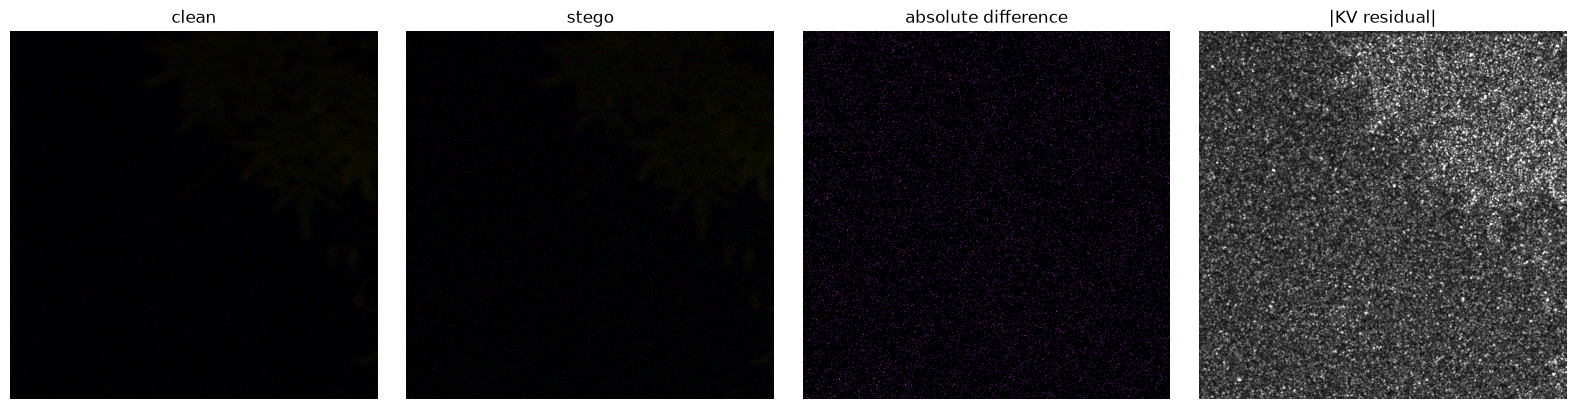

Pair: r00617aa1t:overlap_last:512:0:0:v1
Shapes: clean=(3, 512, 512), stego=(3, 512, 512)
Mean absolute pixel difference: 0.58171; nonzero pixels: 14,035
KV residual range: 0.000 to 10.500


In [6]:
KV_ARRAY = np.array([
    [-1, 2, -2, 2, -1],
    [2, -6, 8, -6, 2],
    [-2, 8, -12, 8, -2],
    [2, -6, 8, -6, 2],
    [-1, 2, -2, 2, -1],
], dtype=np.float32) / 12.0


def read_raw(path: Path) -> torch.Tensor:
    """Read an RGB PNG as CHW float32 values in the original 0-255 range."""
    with Image.open(path) as image:
        array = np.asarray(image.convert("RGB"), dtype=np.uint8).copy()
    return torch.from_numpy(array).permute(2, 0, 1).contiguous().float()


def kv_residual(image: torch.Tensor) -> torch.Tensor:
    """Apply the fixed KV filter independently to R, G, and B."""
    kernel = torch.from_numpy(KV_ARRAY).to(dtype=image.dtype, device=image.device)
    weight = kernel.view(1, 1, 5, 5).repeat(3, 1, 1, 1)
    return F.conv2d(image.unsqueeze(0), weight, padding=2, groups=3).squeeze(0)

example = run_pairs.iloc[0]
if V3_DATA == "png":
    clean_example = read_raw(DATA_ROOT / example["file_clean"])
    stego_example = read_raw(DATA_ROOT / example["file_stego"])
else:
    clean_example, stego_example, _ = otf_data.fixed_train[0]
    clean_example, stego_example = clean_example.float(), stego_example.float()
difference = (stego_example - clean_example).abs().numpy().mean(axis=0)
residual = kv_residual(clean_example).abs().numpy().mean(axis=0)
residual_limit = max(float(np.percentile(residual, 99.5)), 1.0)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow((clean_example.permute(1, 2, 0).numpy() / 255.0).clip(0, 1)); axes[0].set_title("clean")
axes[1].imshow((stego_example.permute(1, 2, 0).numpy() / 255.0).clip(0, 1)); axes[1].set_title("stego")
axes[2].imshow(difference, cmap="magma", vmin=0, vmax=max(float(difference.max()), 1.0)); axes[2].set_title("absolute difference")
axes[3].imshow(residual, cmap="gray", vmin=0, vmax=residual_limit); axes[3].set_title("|KV residual|")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()
print(f"Pair: {example['cover_id']}")
print(f"Shapes: clean={tuple(clean_example.shape)}, stego={tuple(stego_example.shape)}")
print(f"Mean absolute pixel difference: {difference.mean():.5f}; nonzero pixels: {(difference > 0).sum():,}")
print(f"KV residual range: {residual.min():.3f} to {residual.max():.3f}")


## 5. Dataset and DataLoader

Validation and test use clean/stego pairs so their predictions and per-setting metrics stay aligned. With `PAIRED_BATCHES = False`, training uses a separate sample for each image and shuffles those samples independently. Inputs remain raw float32 values from 0 to 255, with no resize or normalization.

OTF workers transfer keyed uint8 CHW groups of four images. The parent joins groups across workers into the final batch, with no normalization or resize. Device conversion is float32 in every model step. PNG still uses its original float32 path.


In [7]:
class PairDataset(Dataset):
    """Load paired tiles for validation, testing, and optional paired training."""

    def __init__(self, frame: pd.DataFrame, train: bool = False):
        self.frame = frame.reset_index(drop=True)
        self.train = train

    def __len__(self) -> int:
        return len(self.frame)

    def __getitem__(self, index: int):
        row = self.frame.iloc[index]
        clean = read_raw(DATA_ROOT / row["file_clean"])
        stego = read_raw(DATA_ROOT / row["file_stego"])
        if self.train:
            clean = augment_image(clean)
            stego = augment_image(stego)
        return clean, stego, index


def augment_image(image: torch.Tensor) -> torch.Tensor:
    """Apply the baseline's random geometric augmentation to one image."""
    if bool(torch.rand(()) < 0.5):
        image = torch.flip(image, dims=(-1,))
    if bool(torch.rand(()) < 0.5):
        image = torch.flip(image, dims=(-2,))
    turns = int(torch.randint(0, 4, ()).item())
    return torch.rot90(image, turns, dims=(-2, -1))


class ImageDataset(Dataset):
    """Expose clean and stego tiles as separate shuffled training samples."""

    def __init__(self, frame: pd.DataFrame, train: bool = False):
        self.train = train
        self.samples = []
        for row in frame.itertuples(index=False):
            self.samples.append((row.file_clean, 0))
            self.samples.append((row.file_stego, 1))

    def __len__(self) -> int:
        return len(self.samples)

    def __getitem__(self, index: int):
        file_name, label = self.samples[index]
        image = read_raw(DATA_ROOT / file_name)
        if self.train:
            image = augment_image(image)
        return image, label, index


if V3_DATA == "png":
    train_frame = run_pairs.loc[run_pairs["split"] == "train"].reset_index(drop=True)
    val_frame = run_pairs.loc[run_pairs["split"] == "val"].reset_index(drop=True)
    test_frame = run_pairs.loc[run_pairs["split"] == "test"].reset_index(drop=True)
    train_dataset = PairDataset(train_frame, train=True) if PAIRED_BATCHES else ImageDataset(train_frame, train=True)
    val_dataset = PairDataset(val_frame, train=False)
    test_dataset = PairDataset(test_frame, train=False)
    NUM_WORKERS = min(8, max(2, (os.cpu_count() or 4) - 2))
    if QUICK:
        NUM_WORKERS = min(2, NUM_WORKERS)
    loader_kwargs = {"num_workers": NUM_WORKERS, "pin_memory": DEVICE.type == "cuda"}
    if NUM_WORKERS > 0:
        loader_kwargs["persistent_workers"] = True
    pair_batch_size = max(1, BATCH_SIZE // 2)
    train_batch_size = pair_batch_size if PAIRED_BATCHES else BATCH_SIZE
    train_loader = DataLoader(train_dataset, batch_size=train_batch_size, shuffle=True, **loader_kwargs)
    val_loader = DataLoader(val_dataset, batch_size=pair_batch_size, shuffle=False, **loader_kwargs)
    test_loader = DataLoader(test_dataset, batch_size=pair_batch_size, shuffle=False, **loader_kwargs)
    train_eval_frame = train_frame.sample(n=min(1000, len(train_frame)), random_state=SEED).reset_index(drop=True)
    train_eval_dataset = PairDataset(train_eval_frame, train=False)
    train_eval_loader = DataLoader(train_eval_dataset, batch_size=pair_batch_size, shuffle=False, **loader_kwargs)
    
    preview_clean, preview_stego, _ = PairDataset(train_frame.head(1), train=False)[0]
    clean_batch = preview_clean.unsqueeze(0)
    stego_batch = preview_stego.unsqueeze(0)
    if PAIRED_BATCHES:
        batch_clean, batch_stego, pair_indices = next(iter(train_loader))
        print(f"paired training batch: clean={tuple(batch_clean.shape)}, stego={tuple(batch_stego.shape)}")
    else:
        image_batch, target_batch, image_indices = next(iter(train_loader))
        print(f"unpaired training batch: images={tuple(image_batch.shape)}, targets={tuple(target_batch.shape)}")
    print(f"num_workers={NUM_WORKERS}; train batches={len(train_loader)}, val batches={len(val_loader)}, test batches={len(test_loader)}")
    print(f"preview clean={tuple(clean_batch.shape)}, preview stego={tuple(stego_batch.shape)}, dtype={clean_batch.dtype}")
    print(f"range: {clean_batch.min().item():.1f} to {clean_batch.max().item():.1f}")
    assert clean_batch.shape == stego_batch.shape
    assert clean_batch.dtype == torch.float32
    assert 0 <= clean_batch.min() and clean_batch.max() <= 255
    
else:
    train_dataset, val_dataset, test_dataset = otf_data.train, otf_data.val, otf_data.test
    train_frame, val_frame, test_frame = otf_data.fixed_train.frame, val_dataset.frame, test_dataset.frame
    NUM_WORKERS = OTF_WORKERS
    train_loader, val_loader, test_loader, train_eval_loader = otf_data.loaders(BATCH_SIZE, NUM_WORKERS, DEVICE.type == "cuda", OTF_PREFETCH)
    clean_preview, stego_preview, _ = otf_data.fixed_train[0]
    clean_batch, stego_batch = clean_preview.float().unsqueeze(0), stego_preview.float().unsqueeze(0)
    byte_images, _, _ = next(iter(val_loader))
    assert byte_images.dtype == torch.uint8
    assert torch.equal(byte_images.to(DEVICE).float(), byte_images.float().to(DEVICE))
    print("UINT8 CHECK device float32 equals old float32 transfer: True")
    print(f"train batches={len(train_loader)}, val batches={len(val_loader)}, test batches={len(test_loader)}; groups=4 images; workers={NUM_WORKERS}")
    otf_data.check_epochs()
    otf_data.print_record()


UINT8 CHECK device float32 equals old float32 transfer: True
train batches=3372, val batches=703, test batches=685; groups=4 images; workers=6
EPOCH CHECK val unchanged: True
EPOCH CHECK test unchanged: True
EPOCH CHECK same train tile key stego epoch0 != epoch1: True
OTF run settings:
{
  "settings": {
    "sources": [
      "raise",
      "div2k"
    ],
    "tile_size": 512,
    "grid": "overlap_last",
    "settings_yaml": null,
    "variants_per_tile": 1,
    "fixed_variants": false,
    "run_seed": 0,
    "train_photo_fraction": 1.0,
    "source_weights": null,
    "source": "cache",
    "cache_root": "/srv/aai3001/otf-cache/v1",
    "buffer_size": 1024,
    "augment": true,
    "paired_batches": false,
    "tensor_dtype": "uint8"
  },
  "source": "cache",
  "grid": "overlap_last",
  "tile_size": 512,
  "run_seed": 0,
  "train_photo_fraction": 1.0,
  "train_photo_selection": [
    {
      "source": "div2k",
      "camera_model": "",
      "available": 680,
      "selected": 680,
  

## 6. Residual model

Batch variance varied about 45-50 times: clipping the KV residual to [-3, 3] limits this scale variation while retaining small LSB residual changes of about +/-1. GroupNorm uses 8 groups (all channel counts are divisible by 8), normalizes each image separately, and has no running statistics.


In [8]:
KV_TENSOR = torch.tensor(KV_ARRAY, dtype=torch.float32)


class KVFilter(nn.Module):
    """Frozen depthwise KV residual filter."""

    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(3, 3, kernel_size=5, padding=2, groups=3, bias=False)
        with torch.no_grad():
            self.conv.weight.copy_(KV_TENSOR.view(1, 1, 5, 5).repeat(3, 1, 1, 1))
        self.conv.weight.requires_grad_(False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.conv(x)


def make_norm(channels: int, norm: str):
    return nn.BatchNorm2d(channels) if norm == "batch" else nn.GroupNorm(8, channels)


class XuNet(nn.Module):
    """Compact Xu-Net-style classifier for 512x512 RGB tiles."""

    def __init__(self, clip_t=CLIP_T, norm=NORM):
        super().__init__()
        self.clip_t = clip_t
        self.kv = KVFilter()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=5, padding=2)
        self.bn1 = make_norm(16, norm)
        self.conv2 = nn.Conv2d(16, 16, kernel_size=5, padding=2)
        self.bn2 = make_norm(16, norm)
        self.conv3 = nn.Conv2d(16, 32, kernel_size=1)
        self.bn3 = make_norm(32, norm)
        self.conv4 = nn.Conv2d(32, 64, kernel_size=1)
        self.bn4 = make_norm(64, norm)
        self.conv5 = nn.Conv2d(64, 128, kernel_size=1)
        self.bn5 = make_norm(128, norm)
        self.pool = nn.AvgPool2d(kernel_size=2, stride=2)
        self.classifier = nn.Linear(128, 2)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.kv(x)
        if self.clip_t is not None:
            x = torch.clamp(x, -self.clip_t, self.clip_t)
        x = self.pool(torch.tanh(self.bn1(torch.abs(self.conv1(x)))))
        x = self.pool(torch.tanh(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = self.pool(F.relu(self.bn4(self.conv4(x))))
        x = self.pool(F.relu(self.bn5(self.conv5(x))))
        x = x.mean(dim=(-2, -1))
        return self.classifier(x)


model_for_count = XuNet()
total_parameters = sum(parameter.numel() for parameter in model_for_count.parameters())
trainable_parameters = sum(parameter.numel() for parameter in model_for_count.parameters() if parameter.requires_grad)
print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")
print(f"Output shape for one batch: {tuple(model_for_count(clean_batch[:1]).shape)}")


Total parameters: 19,453
Trainable parameters: 19,378
Output shape for one batch: (1, 2)


The KV weights must remain fixed during optimization. This cell runs one real optimizer step on a batch and asserts that the frozen filter is unchanged. The expected result is `KV weights unchanged: True`.

In [9]:
probe = XuNet().to(DEVICE)
probe.train()
probe_optimizer = torch.optim.Adam(probe.parameters(), lr=1e-3)
probe_clean = clean_batch.to(DEVICE)
probe_stego = stego_batch.to(DEVICE)
probe_images = torch.cat([probe_clean, probe_stego], dim=0)
probe_targets = torch.cat([
    torch.zeros(probe_clean.shape[0], dtype=torch.long, device=DEVICE),
    torch.ones(probe_stego.shape[0], dtype=torch.long, device=DEVICE),
])
kv_before = probe.kv.conv.weight.detach().clone()
probe_optimizer.zero_grad(set_to_none=True)
probe_loss = F.cross_entropy(probe(probe_images), probe_targets)
probe_loss.backward()
probe_optimizer.step()
kv_unchanged = torch.equal(kv_before, probe.kv.conv.weight.detach())
print(f"Probe loss: {probe_loss.item():.5f}")
print(f"KV weights unchanged: {kv_unchanged}")
assert kv_unchanged


Probe loss: 0.79254
KV weights unchanged: True


## 7. Train

AdamW and StepLR are unchanged. Validation P_E and AUC use all scores for the epoch and respect ties. Save every epoch plus last.ckpt for reliable resume; a separate callback selects the smallest validation P_E. CUDA uses cuDNN benchmark (L4 convolution time 73 to 47 ms/step); ROCm leaves it off. Keep fp32.

ROCM_CONV1_FIX defaults to True (V3_ROCM_CONV1_FIX=False disables it). On ROCm GPU only, it replaces the slow MIOpen 3.6.1 conv1 weight gradient with unfold plus batched matrix multiplication. It needs about 1 GB more memory. If notebooks/rocm_conv1_wgrad.py is missing, the notebook prints a message and uses the standard conv1. CUDA and CPU keep the original convolution.


## Watch training live

CSV and TensorBoard logs stay in the run folder, under logs/csv/run and logs/tb/run. Fixed versions keep resume logs together; CSV rows are preserved on resume. If TensorBoard is missing, the notebook prints one warning and uses CSV only.
Use Scalars / Time Series and select the train and val runs: matching loss and acc tags overlay in different colours. Val also has pe, auc, fa and md. CUSTOM SCALARS combines the train/val loss and accuracy charts in different colours, with separate P_E and AUC axes. Set smoothing to 0 for per-epoch numbers. The layout is written once and kept on resume.

The four-panel training_curves.png is refreshed after every validation epoch (not the sanity check), then at training end. Current training metrics appear after epoch aggregation; the final figure is also shown inline. Validation false alarms and misses use threshold 0.5.

PC, in another terminal:

```sh
podman exec aai3001 tensorboard --logdir /work/checkpoints --bind_all --port 6006
```

Open http://localhost:6006. The current aai3001 container uses pasta networking: although podman port lists no explicit mapping, pasta forwards the listening port automatically. This command was checked with host curl (HTTP 200). If a recreated container does not forward it, publish port 6006 when creating that container; do not assume the old networking setup remains. Stop TensorBoard with Ctrl+C when done.

VM, from the repository root:

```sh
uv run tensorboard --logdir checkpoints --port 6006
```

On the PC, open a second terminal:

```sh
ssh -L 6006:localhost:6006 aai-team@gcp-aai3001
```

Then open http://localhost:6006. Stop the local TensorBoard server before using the same local port for this tunnel.


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/home/aai-team/AAI3001-CVDL/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/checkpoint_connector.py:190: .fit(ckpt_path="last") is set, but there is no last checkpoint available. No checkpoint will be loaded. HINT: Set `ModelCheckpoint(..., save_last=True)`.
You are using a CUDA device ('NVIDIA L4') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
/home/aai-team/AAI3001-CVDL/.venv/lib/python3.12/site-pac

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/home/aai-team/AAI3001-CVDL/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


/home/aai-team/AAI3001-CVDL/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/data.py:123: Your `IterableDataset` has `__len__` defined. In combination with multi-process data loading (when num_workers > 1), `__len__` could be inaccurate if each worker is not configured independently to avoid having duplicate data.


Training: |          | 0/? [00:00<?, ?it/s]OTF EPOCH START 0
Epoch 9: 100%|██████████| 3372/3372 [07:21<00:00,  7.63it/s, v_num=run, val_loss=0.0471, val_acc=0.984, val_pe=0.0148, val_auc=0.998, val_fa=0.00525, val_md=0.0271, train_loss=0.0512, train_acc=0.983]

`Trainer.fit` stopped: `max_epochs=10` reached.


CURVES updated after train end, epoch=10
Epoch 9: 100%|██████████| 3372/3372 [07:22<00:00,  7.63it/s, v_num=run, val_loss=0.0471, val_acc=0.984, val_pe=0.0148, val_auc=0.998, val_fa=0.00525, val_md=0.0271, train_loss=0.0512, train_acc=0.983]
CHECKPOINT CHECK last epoch=9, accepted=9/10, global_step=33720
Training time: 73.81 minutes
Last checkpoint: /srv/aai3001/AAI3001-CVDL/checkpoints/baseline_kv_xunet_v3_clip3_group_otf/last.ckpt
Best checkpoint: /srv/aai3001/AAI3001-CVDL/checkpoints/baseline_kv_xunet_v3_clip3_group_otf/best-epoch07-val_pe0.0146-val_auc0.9974.ckpt
Trainer device: cuda:0
CURVES updated after final, epoch=10


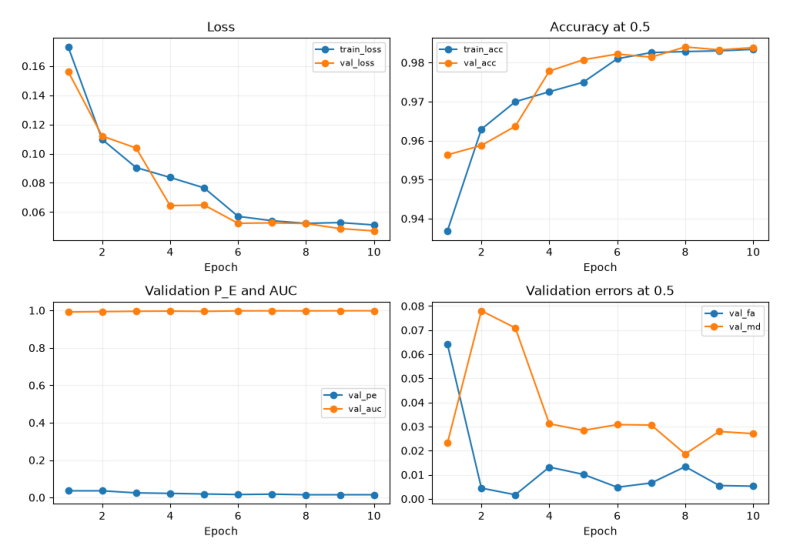

In [10]:
def _threshold_counts(labels_array: np.ndarray, scores_array: np.ndarray) -> tuple[np.ndarray, np.ndarray, int, int]:
    """Count positives and negatives at tied score thresholds."""
    labels_array = np.asarray(labels_array, dtype=np.int64)
    scores_array = np.asarray(scores_array, dtype=np.float64)
    if labels_array.size == 0:
        return np.array([], dtype=np.int64), np.array([], dtype=np.int64), 0, 0
    order = np.argsort(-scores_array, kind="mergesort")
    sorted_scores = scores_array[order]
    sorted_labels = labels_array[order]
    group_ends = np.flatnonzero(sorted_scores[1:] != sorted_scores[:-1]) + 1
    group_ends = np.r_[group_ends, len(sorted_scores)]
    cumulative_positive = np.cumsum(sorted_labels == 1, dtype=np.int64)
    cumulative_negative = np.cumsum(sorted_labels == 0, dtype=np.int64)
    return (
        cumulative_positive[group_ends - 1],
        cumulative_negative[group_ends - 1],
        int((labels_array == 1).sum()),
        int((labels_array == 0).sum()),
    )


def auc_numpy(labels_array: np.ndarray, scores_array: np.ndarray) -> float:
    """Compute ROC AUC with one sort and tied-score groups."""
    true_positive, false_positive, positives, negatives = _threshold_counts(labels_array, scores_array)
    if positives == 0 or negatives == 0:
        return 0.0
    denominator_positive = float(positives)
    denominator_negative = float(negatives)
    true_positive_rate = np.r_[0.0, true_positive / denominator_positive, true_positive[-1] / denominator_positive]
    false_positive_rate = np.r_[0.0, false_positive / denominator_negative, false_positive[-1] / denominator_negative]
    return float(np.trapezoid(true_positive_rate, false_positive_rate))


def probability_error(labels_array: np.ndarray, scores_array: np.ndarray) -> float:
    """Compute minimum P_E with one sort and tied-score groups."""
    true_positive, false_positive, positives, negatives = _threshold_counts(labels_array, scores_array)
    if positives == 0 and negatives == 0:
        return 0.0
    if negatives:
        false_alarm = np.r_[0.0, false_positive / negatives, false_positive[-1] / negatives]
    else:
        false_alarm = np.zeros(len(true_positive) + 2, dtype=np.float64)
    if positives:
        missed_detection = np.r_[1.0, (positives - true_positive) / positives, 0.0]
    else:
        missed_detection = np.zeros(len(true_positive) + 2, dtype=np.float64)
    return float(np.min((false_alarm + missed_detection) / 2.0))


class SteganalysisModule(L.LightningModule):
    """Lightning wrapper for paired or unpaired image batches."""

    def __init__(self, lr: float = 1e-3, max_epochs: int = 2, weight_decay: float = 1e-4, paired_batches: bool = False, clip_t=CLIP_T, norm=NORM):
        super().__init__()
        self.save_hyperparameters()
        self.net = XuNet(clip_t=clip_t, norm=norm)
        if ROCM_CONV1_FIX_ACTIVE:
            self.net.conv1 = UnfoldWgradConv2d.from_conv(self.net.conv1)
        self.validation_scores = []
        self.validation_labels = []

    def pair_logits_targets(self, batch):
        clean, stego, _ = batch
        images = torch.cat([clean, stego], dim=0).float()
        targets = torch.cat([
            torch.zeros(clean.shape[0], dtype=torch.long, device=clean.device),
            torch.ones(stego.shape[0], dtype=torch.long, device=stego.device),
        ])
        return self.net(images), targets

    def training_logits_targets(self, batch):
        if self.hparams.paired_batches:
            return self.pair_logits_targets(batch)
        images, targets, _ = batch
        return self.net(images.float()), targets

    def training_step(self, batch, batch_idx):
        logits, targets = self.training_logits_targets(batch)
        loss = F.cross_entropy(logits, targets)
        accuracy = (logits.argmax(dim=1) == targets).float().mean()
        self.log("train_loss", loss, on_step=False, on_epoch=True, prog_bar=True, batch_size=targets.numel())
        self.log("train_acc", accuracy, on_step=False, on_epoch=True, prog_bar=True, batch_size=targets.numel())
        return {"loss": loss, "accuracy": accuracy.detach(), "count": targets.numel()}

    def on_validation_epoch_start(self):
        self.validation_scores.clear()
        self.validation_labels.clear()

    def validation_step(self, batch, batch_idx):
        logits, targets = self.pair_logits_targets(batch)
        loss = F.cross_entropy(logits, targets)
        accuracy = (logits.argmax(dim=1) == targets).float().mean()
        self.validation_scores.append(logits.softmax(dim=1)[:, 1].detach().cpu())
        self.validation_labels.append(targets.detach().cpu())
        self.log("val_loss", loss, on_step=False, on_epoch=True, prog_bar=True, batch_size=targets.numel())
        self.log("val_acc", accuracy, on_step=False, on_epoch=True, prog_bar=True, batch_size=targets.numel())

    def on_validation_epoch_end(self):
        scores = torch.cat(self.validation_scores).numpy()
        labels_array = torch.cat(self.validation_labels).numpy()
        self.log("val_pe", probability_error(labels_array, scores), prog_bar=True)
        self.log("val_auc", auc_numpy(labels_array, scores), prog_bar=True)
        clean_scores = scores[labels_array == 0]
        stego_scores = scores[labels_array == 1]
        self.log("val_fa", float((clean_scores >= 0.5).mean()), prog_bar=True)
        self.log("val_md", float((stego_scores < 0.5).mean()), prog_bar=True)
        self.validation_scores.clear()
        self.validation_labels.clear()

    def configure_optimizers(self):
        optimizer = torch.optim.AdamW(
            self.parameters(), lr=self.hparams.lr, weight_decay=self.hparams.weight_decay
        )
        scheduler = torch.optim.lr_scheduler.StepLR(
            optimizer, step_size=max(1, self.hparams.max_epochs // 2), gamma=0.1
        )
        return {"optimizer": optimizer, "lr_scheduler": scheduler}


from lightning.pytorch.loggers import CSVLogger, TensorBoardLogger
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
import csv

class AppendCSVLogger(CSVLogger):
    """Keep existing CSV rows when Lightning opens a fixed-version run."""

    @property
    def experiment(self):
        if self._experiment is None:
            path = Path(self.log_dir) / "metrics.csv"
            previous = path.read_bytes() if path.exists() else None
            writer = super().experiment  # Lightning normally removes an existing CSV here.
            if previous is not None:
                path.write_bytes(previous)
                writer.metrics_keys = next(csv.reader(previous.decode().splitlines()))
        return super().experiment


class TrainingCurves(L.Callback):
    """Draw with an Agg canvas only; do not change the notebook's inline backend."""

    def __init__(self, csv_logger, run_dir):
        self.csv_logger = csv_logger
        self.run_dir = Path(run_dir)
        self.history = {}

    def state_dict(self):
        return {"history": self.history}

    def load_state_dict(self, state_dict):
        self.history = state_dict.get("history", {})

    def redraw(self, trainer, phase):
        self.csv_logger.save()
        path = Path(self.csv_logger.log_dir) / "metrics.csv"
        if path.exists():
            frame = pd.read_csv(path)
            for _, row in frame.iterrows():
                if pd.isna(row.get("epoch")):
                    continue
                epoch = int(row["epoch"])
                values = self.history.setdefault(epoch, {})
                values.update({key: float(value) for key, value in row.items()
                               if key not in {"epoch", "step"} and pd.notna(value)})
        if phase == "validation":
            values = self.history.setdefault(trainer.current_epoch, {})
            for key in ("val_loss", "val_acc", "val_pe", "val_auc", "val_fa", "val_md"):
                if key in trainer.callback_metrics:
                    values[key] = float(trainer.callback_metrics[key].detach().cpu())
        if not self.history:
            return
        frame = pd.DataFrame.from_dict(self.history, orient="index").sort_index()
        fig = Figure(figsize=(10, 7), dpi=100)
        FigureCanvasAgg(fig)
        axes = fig.subplots(2, 2).flat
        for ax, keys, title in zip(axes,
                [("train_loss", "val_loss"), ("train_acc", "val_acc"),
                 ("val_pe", "val_auc"), ("val_fa", "val_md")],
                ["Loss", "Accuracy at 0.5", "Validation P_E and AUC", "Validation errors at 0.5"]):
            for key in keys:
                if key in frame:
                    ax.plot(frame.index + 1, frame[key], marker="o", label=key)
            ax.set(title=title, xlabel="Epoch")
            ax.grid(alpha=0.2)
            if ax.lines:
                ax.legend(fontsize=8)
        fig.tight_layout()
        fig.savefig(self.run_dir / "training_curves.png")
        print(f"CURVES updated after {phase}, epoch={trainer.current_epoch}", flush=True)

    def on_validation_end(self, trainer, pl_module):
        if not trainer.sanity_checking:
            self.redraw(trainer, "validation")

    def on_train_epoch_end(self, trainer, pl_module):
        self.redraw(trainer, "train epoch")

    def on_train_end(self, trainer, pl_module):
        self.redraw(trainer, "train end")


class PerEpochScalars(L.Callback):
    """Use separate train/val runs so matching tags get different colours."""

    def __init__(self, log_root):
        from torch.utils.tensorboard import SummaryWriter
        self.train_writer = SummaryWriter(str(Path(log_root) / "train"))
        self.val_writer = SummaryWriter(str(Path(log_root) / "val"))
        self.last_step = -1
        self.loss_sum = None
        self.accuracy_sum = None
        self.count = 0

    def state_dict(self):
        return {"last_step": self.last_step}

    def load_state_dict(self, state_dict):
        self.last_step = state_dict.get("last_step", -1)

    def on_train_epoch_start(self, trainer, pl_module):
        self.loss_sum = None
        self.accuracy_sum = None
        self.count = 0

    def on_train_batch_end(self, trainer, pl_module, outputs, batch, batch_idx):
        count = outputs["count"]
        loss = outputs["loss"].detach() * count
        accuracy = outputs["accuracy"].detach() * count
        self.loss_sum = loss if self.loss_sum is None else self.loss_sum + loss
        self.accuracy_sum = accuracy if self.accuracy_sum is None else self.accuracy_sum + accuracy
        self.count += count

    def on_validation_end(self, trainer, pl_module):
        if trainer.sanity_checking or trainer.global_step <= self.last_step:
            return
        step = trainer.global_step
        if self.count:
            self.train_writer.add_scalar("loss", float(self.loss_sum / self.count), step)
            self.train_writer.add_scalar("acc", float(self.accuracy_sum / self.count), step)
        for tag, key in [("loss", "val_loss"), ("acc", "val_acc"), ("pe", "val_pe"),
                         ("auc", "val_auc"), ("fa", "val_fa"), ("md", "val_md")]:
            self.val_writer.add_scalar(tag, float(trainer.callback_metrics[key]), step)
        self.train_writer.flush()
        self.val_writer.flush()
        self.last_step = step

    def on_train_end(self, trainer, pl_module):
        self.train_writer.close()
        self.val_writer.close()


def select_best_checkpoint(callback_path, run_folder):
    import re
    if callback_path and Path(callback_path).is_file():
        return str(callback_path)
    candidates = sorted(path for path in Path(run_folder).glob("best-*.ckpt") if path.is_file())
    if not candidates:
        raise FileNotFoundError(f"No best checkpoint found in {run_folder}: callback path {callback_path!r} is missing and no best-*.ckpt files exist.")
    if len(candidates) == 1:
        selected = candidates[0]
    else:
        def score(path):
            match = re.search(r"-val_pe([0-9]+(?:\.[0-9]+)?(?:[eE][+-]?[0-9]+)?)", path.name)
            if match is None:
                raise ValueError(f"Cannot select the lowest val_pe: {path.name} has no val_pe in its name.")
            return float(match.group(1)), path.name
        selected = min(candidates, key=score)
    print(f"Best checkpoint fallback: callback path missing; using {selected}")
    return str(selected)


class OTF_Epoch(L.Callback):
    def on_fit_start(self, trainer, pl_module):
        otf_data.train.set_epoch(int(trainer.current_epoch))
    def on_train_epoch_start(self, trainer, pl_module):
        otf_data.train.set_epoch(int(trainer.current_epoch))
        print(f"OTF EPOCH START {trainer.current_epoch}", flush=True)
    def on_train_epoch_end(self, trainer, pl_module):
        # Set the next epoch before Lightning creates/prefetches its iterator.
        otf_data.train.set_epoch(int(trainer.current_epoch)+1)

checkpoint_dir = CHECKPOINT_ROOT / RUN_NAME
checkpoint_dir.mkdir(parents=True, exist_ok=True)
if V3_DATA == "otf":
    otf_data.save_record(checkpoint_dir / "data_run_settings.json")
csv_logger = AppendCSVLogger(save_dir=str(checkpoint_dir / "logs"), name="csv", version="run", flush_logs_every_n_steps=1)
run_loggers = [csv_logger]
try:
    import tensorboard
except ImportError:
    print("WARNING: TensorBoard is unavailable; using CSV logging only.")
else:
    tb_logger = TensorBoardLogger(save_dir=str(checkpoint_dir / "logs"), name="tb", version="run")
    run_loggers.append(tb_logger)
    custom_layout = {"Training": {
        "Loss": ["Multiline", ["^loss$"]],
        "Accuracy": ["Multiline", ["^acc$"]],
        "Errors at 0.5": ["Multiline", ["^fa$", "^md$"]],
        "Detection error P_E": ["Multiline", ["^pe$"]],
        "AUC": ["Multiline", ["^auc$"]],
    }}
    layout_marker = Path(tb_logger.log_dir) / "custom_scalars_layout.json"
    layout_text = json.dumps(custom_layout, sort_keys=True)
    if not layout_marker.exists() or layout_marker.read_text() != layout_text:
        tb_logger.experiment.add_custom_scalars(custom_layout)
        tb_logger.experiment.flush()
        layout_marker.write_text(layout_text)
curves_callback = TrainingCurves(csv_logger, checkpoint_dir)
per_epoch_callback = PerEpochScalars(checkpoint_dir / "logs" / "tb") if len(run_loggers) > 1 else None
every_epoch_callback = L.pytorch.callbacks.ModelCheckpoint(
    dirpath=str(checkpoint_dir),
    filename="epoch{epoch:02d}-val_pe{val_pe:.4f}-val_auc{val_auc:.4f}",
    auto_insert_metric_name=False, save_top_k=-1, save_last=True,
    every_n_epochs=1, save_on_train_epoch_end=False,
)
checkpoint_callback = L.pytorch.callbacks.ModelCheckpoint(
    dirpath=str(checkpoint_dir),
    filename="best-epoch{epoch:02d}-val_pe{val_pe:.4f}-val_auc{val_auc:.4f}",
    auto_insert_metric_name=False, monitor="val_pe", mode="min", save_top_k=1,
    every_n_epochs=1, save_on_train_epoch_end=False,
)
trainer = L.Trainer(
    max_epochs=EPOCHS,
    accelerator="gpu" if DEVICE.type == "cuda" else "cpu",
    devices=1,
    # Lightning 2.6.6 moves checkpoints last but keeps their relative order.
    # Save the best callback state before the every-epoch callback writes last.ckpt.
    callbacks=[curves_callback, checkpoint_callback, every_epoch_callback] + ([per_epoch_callback] if per_epoch_callback else []) + ([OTF_Epoch()] if V3_DATA == "otf" else []),
    logger=run_loggers,
    default_root_dir=str(CHECKPOINT_ROOT),
    log_every_n_steps=50,
    deterministic=False,
)
training_started = time.perf_counter()
assert trainer.checkpoint_callbacks == [checkpoint_callback, every_epoch_callback], "best checkpoint must run before last.ckpt is saved"
lightning_model = SteganalysisModule(max_epochs=EPOCHS, paired_batches=PAIRED_BATCHES)
trainer.fit(lightning_model, train_loader, val_loader, ckpt_path="last")
training_seconds = time.perf_counter() - training_started
best_checkpoint = select_best_checkpoint(checkpoint_callback.best_model_path, checkpoint_dir)
last_saved = torch.load(every_epoch_callback.last_model_path, map_location="cpu", weights_only=False)
assert last_saved["epoch"] in {EPOCHS - 1, EPOCHS}, "last.ckpt must be final epoch or no-op resume"
assert last_saved["global_step"] == EPOCHS * len(train_loader), "no extra training steps allowed"
print(f"CHECKPOINT CHECK last epoch={last_saved['epoch']}, accepted={EPOCHS - 1}/{EPOCHS}, global_step={last_saved['global_step']}")
assert len(list(checkpoint_dir.glob("epoch*.ckpt"))) == EPOCHS
del last_saved
print(f"Training time: {training_seconds / 60:.2f} minutes")
print(f"Last checkpoint: {every_epoch_callback.last_model_path}")
print(f"Best checkpoint: {best_checkpoint}")
print(f"Trainer device: {trainer.strategy.root_device}")

curves_callback.redraw(trainer, "final")
curves_image = plt.imread(checkpoint_dir / "training_curves.png")
plt.figure(figsize=(10, 7))
plt.imshow(curves_image)
plt.axis("off")
plt.show()


## 8. Test the best validation-P_E checkpoint

Report accuracy at 0.5, AUC, and P_E. The held-out test set does not select a checkpoint.


In [11]:
def _threshold_counts(labels_array: np.ndarray, scores_array: np.ndarray) -> tuple[np.ndarray, np.ndarray, int, int]:
    """Count positives and negatives at tied score thresholds."""
    labels_array = np.asarray(labels_array, dtype=np.int64)
    scores_array = np.asarray(scores_array, dtype=np.float64)
    if labels_array.size == 0:
        return np.array([], dtype=np.int64), np.array([], dtype=np.int64), 0, 0
    order = np.argsort(-scores_array, kind="mergesort")
    sorted_scores = scores_array[order]
    sorted_labels = labels_array[order]
    group_ends = np.flatnonzero(sorted_scores[1:] != sorted_scores[:-1]) + 1
    group_ends = np.r_[group_ends, len(sorted_scores)]
    cumulative_positive = np.cumsum(sorted_labels == 1, dtype=np.int64)
    cumulative_negative = np.cumsum(sorted_labels == 0, dtype=np.int64)
    return (
        cumulative_positive[group_ends - 1],
        cumulative_negative[group_ends - 1],
        int((labels_array == 1).sum()),
        int((labels_array == 0).sum()),
    )


def auc_numpy(labels_array: np.ndarray, scores_array: np.ndarray) -> float:
    """Compute ROC AUC with one sort and tied-score groups."""
    true_positive, false_positive, positives, negatives = _threshold_counts(labels_array, scores_array)
    if positives == 0 or negatives == 0:
        return 0.0
    denominator_positive = float(positives)
    denominator_negative = float(negatives)
    true_positive_rate = np.r_[0.0, true_positive / denominator_positive, true_positive[-1] / denominator_positive]
    false_positive_rate = np.r_[0.0, false_positive / denominator_negative, false_positive[-1] / denominator_negative]
    return float(np.trapezoid(true_positive_rate, false_positive_rate))


def probability_error(labels_array: np.ndarray, scores_array: np.ndarray) -> float:
    """Compute minimum P_E with one sort and tied-score groups."""
    true_positive, false_positive, positives, negatives = _threshold_counts(labels_array, scores_array)
    if positives == 0 and negatives == 0:
        return 0.0
    if negatives:
        false_alarm = np.r_[0.0, false_positive / negatives, false_positive[-1] / negatives]
    else:
        false_alarm = np.zeros(len(true_positive) + 2, dtype=np.float64)
    if positives:
        missed_detection = np.r_[1.0, (positives - true_positive) / positives, 0.0]
    else:
        missed_detection = np.zeros(len(true_positive) + 2, dtype=np.float64)
    return float(np.min((false_alarm + missed_detection) / 2.0))


def predict_pairs(model: SteganalysisModule, loader: DataLoader) -> pd.DataFrame:
    """Predict clean and stego probabilities while retaining pair metadata."""
    model.eval()
    frame = loader.dataset.frame
    rows = []
    with torch.inference_mode():
        for clean, stego, indices in loader:
            clean = clean.to(DEVICE, dtype=torch.float32, non_blocking=True)
            stego = stego.to(DEVICE, dtype=torch.float32, non_blocking=True)
            probabilities = torch.softmax(model.net(torch.cat([clean, stego], dim=0)), dim=1)[:, 1]
            count = clean.shape[0]
            clean_probabilities = probabilities[:count].cpu().numpy()
            stego_probabilities = probabilities[count:].cpu().numpy()
            for position, pair_index in enumerate(indices.tolist()):
                row = frame.iloc[int(pair_index)]
                common = {
                    "cover_id": row["cover_id"],
                    "source_photo": row["source_photo"],
                    "camera_model": row["camera_model"],
                    "k": row["k"],
                    "bit_mode": row["bit_mode"],
                    "method": row["method"],
                    "placement": row["placement"],
                    "payload_kind": row["payload_kind"],
                    "bpp_actual": row["bpp_actual"],
                }
                if V3_DATA == "otf":
                    common.update(row.to_dict())
                    common["data_mode"] = "otf"
                else:
                    common["source"] = "raise"
                rows.append({**common, "file": row.get("file_clean", str(row["cover_id"])+":clean"), "label": 0, "prob_stego": float(clean_probabilities[position])})
                rows.append({**common, "file": row.get("file_stego", str(row["cover_id"])+":stego"), "label": 1, "prob_stego": float(stego_probabilities[position])})
    return pd.DataFrame(rows)


best_model = SteganalysisModule.load_from_checkpoint(best_checkpoint, map_location=DEVICE)
best_model.to(DEVICE)
train_predictions = predict_pairs(best_model, train_eval_loader)
val_predictions = predict_pairs(best_model, val_loader)
predictions = predict_pairs(best_model, test_loader)

def prediction_accuracy(frame: pd.DataFrame) -> float:
    y_true = frame["label"].to_numpy(dtype=np.int64)
    y_score = frame["prob_stego"].to_numpy(dtype=np.float64)
    return float(((y_score >= 0.5).astype(np.int64) == y_true).mean())

print(f"Train eval images: {len(train_predictions):,}; accuracy: {prediction_accuracy(train_predictions):.4f}")
print(f"Validation eval images: {len(val_predictions):,}; accuracy: {prediction_accuracy(val_predictions):.4f}")
print(f"Test eval images: {len(predictions):,}; accuracy: {prediction_accuracy(predictions):.4f}")
y_true = predictions["label"].to_numpy(dtype=np.int64)
y_score = predictions["prob_stego"].to_numpy(dtype=np.float64)
y_hat = (y_score >= 0.5).astype(np.int64)
accuracy = float((y_hat == y_true).mean())
auc = auc_numpy(y_true, y_score)
p_e = probability_error(y_true, y_score)
print(f"Test images: {len(predictions):,}")
print(f"Accuracy: {accuracy:.4f}")
print(f"AUC: {auc:.4f}")
print(f"P_E: {p_e:.4f}")


Train eval images: 2,000; accuracy: 0.9785
Validation eval images: 22,476; accuracy: 0.9840
Test eval images: 21,912; accuracy: 0.9818
Test images: 21,912
Accuracy: 0.9818
AUC: 0.9975
P_E: 0.0170


### Metric implementation check

This small check compares the fast cumulative-count implementations with the original threshold loops on 500 scores containing ties. The expected result is two `True` lines within `1e-12`; tied scores must move together.

In [12]:
def reference_auc(labels_array: np.ndarray, scores_array: np.ndarray) -> float:
    thresholds = np.r_[np.inf, np.sort(np.unique(scores_array))[::-1], -np.inf]
    positives = max(int((labels_array == 1).sum()), 1)
    negatives = max(int((labels_array == 0).sum()), 1)
    tpr = []
    fpr = []
    for threshold in thresholds:
        predicted = scores_array >= threshold
        tpr.append(float(((predicted == 1) & (labels_array == 1)).sum()) / positives)
        fpr.append(float(((predicted == 1) & (labels_array == 0)).sum()) / negatives)
    return float(np.trapezoid(np.asarray(tpr), np.asarray(fpr)))


def reference_probability_error(labels_array: np.ndarray, scores_array: np.ndarray) -> float:
    positives = labels_array == 1
    negatives = labels_array == 0
    thresholds = np.r_[np.inf, np.sort(np.unique(scores_array))[::-1], -np.inf]
    errors = []
    for threshold in thresholds:
        predicted = scores_array >= threshold
        p_fa = float(predicted[negatives].mean()) if negatives.any() else 0.0
        p_md = float((~predicted[positives]).mean()) if positives.any() else 0.0
        errors.append((p_fa + p_md) / 2.0)
    return float(min(errors))

check_rng = np.random.default_rng(123)
check_labels = check_rng.integers(0, 2, size=500, dtype=np.int64)
check_scores = np.round(check_rng.random(500), 2)
assert np.unique(check_scores).size < len(check_scores), "test array must contain ties"
fast_auc = auc_numpy(check_labels, check_scores)
reference_auc_value = reference_auc(check_labels, check_scores)
fast_p_e = probability_error(check_labels, check_scores)
reference_p_e = reference_probability_error(check_labels, check_scores)
assert np.isclose(fast_auc, reference_auc_value, atol=1e-12, rtol=0)
assert np.isclose(fast_p_e, reference_p_e, atol=1e-12, rtol=0)
print(f"AUC agrees within 1e-12: {np.isclose(fast_auc, reference_auc_value, atol=1e-12, rtol=0)}")
print(f"P_E agrees within 1e-12: {np.isclose(fast_p_e, reference_p_e, atol=1e-12, rtol=0)}")


AUC agrees within 1e-12: True
P_E agrees within 1e-12: True


## 9. Per-setting `P_E`

For every stego setting, this cell adds its paired clean image and recomputes `P_E`. It reports rows by combined `bit_mode/k`, bit mode, method, placement, method × placement, payload kind, and the requested bpp bins. The expected result is a table with pair counts and a `P_E` value for each setting present in the test subset.

In [13]:
stego_predictions = predictions.loc[predictions["label"] == 1].copy()
clean_predictions = predictions.loc[predictions["label"] == 0].copy()
stego_predictions["bit_mode_k"] = (
    stego_predictions["bit_mode"].astype(str) + "/" + pd.to_numeric(stego_predictions["k"], errors="raise").astype(int).astype(str)
)
stego_predictions["method_x_placement"] = (
    stego_predictions["method"].astype(str) + "/" + stego_predictions["placement"].astype(str)
)
if V3_DATA == "otf":
    stego_predictions["bpp_bin"] = complete_bpp_bins(stego_predictions["bpp_actual"])
else:
    stego_predictions["bpp_bin"] = pd.cut(
        pd.to_numeric(stego_predictions["bpp_actual"], errors="coerce"),
        bins=[0.05, 0.15, 0.30, 0.50],
        labels=["0.05-0.15", "0.15-0.30", "0.30-0.50"],
        include_lowest=True,
        right=True,
    )
assert not stego_predictions["bpp_bin"].isna().any(), "bpp bins must retain every pair"
print("BPP BIN COUNTS (pairs):")
print(stego_predictions["bpp_bin"].value_counts(sort=False).to_string())

setting_rows = []
setting_specs = [("source", "source"), ("camera_model", "camera_model"),
    ("bit_mode/k", "bit_mode_k"),
    ("bit_mode", "bit_mode"),
    ("method", "method"),
    ("placement", "placement"),
    ("method x placement", "method_x_placement"),
    ("payload_kind", "payload_kind"),
    ("bpp_bin", "bpp_bin"),
]
for setting_label, setting_column in setting_specs:
    for value, group in stego_predictions.groupby(setting_column, dropna=False, observed=True):
        if pd.isna(value):
            continue
        cover_ids = set(group["cover_id"])
        paired_clean = clean_predictions.loc[clean_predictions["cover_id"].isin(cover_ids)]
        paired_images = pd.concat([paired_clean, group], ignore_index=True)
        group_labels = paired_images["label"].to_numpy(dtype=np.int64)
        group_scores = paired_images["prob_stego"].to_numpy(dtype=np.float64)
        setting_rows.append({
            "setting": setting_label,
            "value": str(value),
            "pairs": len(group),
            "P_E": probability_error(group_labels, group_scores),
        })
per_setting = pd.DataFrame(setting_rows, columns=["setting", "value", "pairs", "P_E"])
print(per_setting.to_string(index=False))


BPP BIN COUNTS (pairs):
bpp_bin
<=0.05          0
0.05-0.15    2428
0.15-0.30    4141
0.30-0.50    4387
>0.50           0
           setting              value  pairs      P_E
            source              div2k   1228 0.057410
            source              raise   9728 0.011153
      camera_model          NIKON D40     24 0.000000
      camera_model        NIKON D7000   7490 0.011482
      camera_model          NIKON D90   2214 0.009937
      camera_model     not_applicable   1228 0.057410
        bit_mode/k           lowest/1    682 0.060117
        bit_mode/k           lowest/2    672 0.020089
        bit_mode/k           lowest/3    691 0.006512
        bit_mode/k           lowest/4    677 0.004431
        bit_mode/k           lowest/5    705 0.003546
        bit_mode/k           lowest/6    636 0.003145
        bit_mode/k           lowest/7    713 0.005610
        bit_mode/k           lowest/8    713 0.014727
        bit_mode/k            plane/1    750 0.052000
        bit_mo

## 10. Save predictions

The final cell saves one row per test image under the run checkpoint folder, including the file, label, predicted stego probability, source photo, and setting metadata. The expected result is a CSV that can reproduce the aggregate and per-setting metrics.

In [14]:
predictions_path = checkpoint_dir / "test_predictions.csv"
predictions.to_csv(predictions_path, index=False)
print(f"Saved {len(predictions):,} predictions to {predictions_path}")
print(f"Run folder contents: {[path.name for path in sorted(checkpoint_dir.iterdir())]}")


Saved 21,912 predictions to /srv/aai3001/AAI3001-CVDL/checkpoints/baseline_kv_xunet_v3_clip3_group_otf/test_predictions.csv
Run folder contents: ['best-epoch07-val_pe0.0146-val_auc0.9974.ckpt', 'data_run_settings.json', 'epoch00-val_pe0.0357-val_auc0.9916.ckpt', 'epoch01-val_pe0.0356-val_auc0.9934.ckpt', 'epoch02-val_pe0.0247-val_auc0.9955.ckpt', 'epoch03-val_pe0.0219-val_auc0.9964.ckpt', 'epoch04-val_pe0.0187-val_auc0.9950.ckpt', 'epoch05-val_pe0.0158-val_auc0.9976.ckpt', 'epoch06-val_pe0.0177-val_auc0.9978.ckpt', 'epoch07-val_pe0.0146-val_auc0.9974.ckpt', 'epoch08-val_pe0.0147-val_auc0.9981.ckpt', 'epoch09-val_pe0.0148-val_auc0.9981.ckpt', 'last.ckpt', 'logs', 'test_predictions.csv', 'training_curves.png']


## 11. Batch-dependence checks
Compare evaluation with mixed batches, all-clean (e) and all-stego (f) batches. GroupNorm must give the same logits in train and eval mode for identical images; the sampled aggregate accuracies need not be identical.


In [15]:
from copy import deepcopy
from concurrent.futures import ThreadPoolExecutor

# Reuse the exact seed-0 pair samples from the earlier diagnoses.
check_count = 32 if QUICK else 1000
check_batches = 2 if QUICK else 63
pool = ThreadPoolExecutor(max_workers=6)
for split_name in ("train", "val"):
    if V3_DATA == "png":
        check_frame = pair_splits.loc[pair_splits["split"] == split_name].sample(n=check_count, random_state=0).reset_index(drop=True)
        check_dataset = PairDataset(check_frame)
    else:
        base = otf_data.fixed_train if split_name == "train" else FixedPairs(otf_data.corpus, "val", EVAL_PROFILE)
        check_dataset = fixed_subset(base, min(check_count,len(base)), 0)
        check_frame = check_dataset.frame
        otf_data.record.setdefault("diagnostic_pair_ids", {})[split_name] = check_frame["cover_id"].tolist()
    loader = DataLoader(check_dataset, batch_size=16, shuffle=False, num_workers=6 if V3_DATA == "png" else 0)
    eval_copy = deepcopy(best_model.net).to(DEVICE).eval()
    total_loss = correct = count = 0
    with torch.no_grad():
        for clean, stego, _ in loader:
            images = torch.cat([clean, stego]).to(DEVICE, dtype=torch.float32)
            targets = torch.cat([torch.zeros(len(clean), dtype=torch.long), torch.ones(len(stego), dtype=torch.long)]).to(DEVICE)
            logits = eval_copy(images)
            total_loss += float(F.cross_entropy(logits, targets, reduction="sum"))
            correct += int((logits.argmax(1) == targets).sum())
            count += len(targets)
    print(f"CHECK {split_name} a eval accuracy={correct/count:.6f} loss={total_loss/count:.6f}", flush=True)
    for mode in ("c", "e", "f"):
        check_model = deepcopy(best_model.net).to(DEVICE).train()
        rng = np.random.default_rng(200 + (split_name == "val"))
        correct = count = prob_sum = 0
        max_mode_difference = 0.0
        with torch.no_grad():
            for _ in range(check_batches):
                indices = rng.choice(len(check_frame), size=32, replace=False)
                mixed = rng.permutation(np.r_[np.zeros(16, dtype=int), np.ones(16, dtype=int)])
                targets_np = mixed if mode == "c" else np.zeros(32, dtype=int) if mode == "e" else np.ones(32, dtype=int)
                if V3_DATA == "png":
                    paths = [DATA_ROOT / check_frame.iloc[int(i)]["file_stego" if label else "file_clean"] for i,label in zip(indices, targets_np)]
                    images = torch.stack(list(pool.map(read_raw, paths))).to(DEVICE)
                else:
                    images = torch.stack([check_dataset[int(i)][int(label)] for i,label in zip(indices,targets_np)]).to(DEVICE,dtype=torch.float32)
                targets = torch.tensor(targets_np, dtype=torch.long, device=DEVICE)
                logits = check_model(images)
                if NORM == "group":
                    # Compare exactly the same images, not two different random samples.
                    eval_logits = eval_copy(images)
                    difference = float((logits - eval_logits).abs().max())
                    max_mode_difference = max(max_mode_difference, difference)
                    assert torch.allclose(logits, eval_logits, atol=1e-5, rtol=1e-5)
                correct += int((logits.argmax(1) == targets).sum())
                prob_sum += float(logits.softmax(1)[:, 1].sum())
                count += len(targets)
        print(f"CHECK {split_name} {mode} train-normalization accuracy={correct/count:.6f} mean_prob_stego={prob_sum/count:.6f}", flush=True)
        if NORM == "group":
            print(f"GroupNorm train/eval match on identical images: max logit difference={max_mode_difference:.8g}")
        del check_model
    del eval_copy
pool.shutdown()

if V3_DATA == "otf":
    otf_data.save_record(checkpoint_dir / "data_run_settings.json")


CHECK train a eval accuracy=0.978500 loss=0.066043
CHECK train c train-normalization accuracy=0.979663 mean_prob_stego=0.512040
GroupNorm train/eval match on identical images: max logit difference=0
CHECK train e train-normalization accuracy=0.983135 mean_prob_stego=0.046045
GroupNorm train/eval match on identical images: max logit difference=0
CHECK train f train-normalization accuracy=0.975694 mean_prob_stego=0.975202
GroupNorm train/eval match on identical images: max logit difference=0
CHECK val a eval accuracy=0.979000 loss=0.061983
CHECK val c train-normalization accuracy=0.979167 mean_prob_stego=0.506653
GroupNorm train/eval match on identical images: max logit difference=0
CHECK val e train-normalization accuracy=0.984623 mean_prob_stego=0.041041
GroupNorm train/eval match on identical images: max logit difference=0
CHECK val f train-normalization accuracy=0.968254 mean_prob_stego=0.965851
GroupNorm train/eval match on identical images: max logit difference=0


## 12. Save the evaluation breakdown
Notebook 02 writes per-setting metrics and annotated k-by-bpp heatmaps beside test_predictions.csv.


Metadata: self-contained OTF predictions; no raise512-run1 lookup
Root: /srv/aai3001/AAI3001-CVDL/notebooks
Predictions: /srv/aai3001/AAI3001-CVDL/checkpoints/baseline_kv_xunet_v3_clip3_group_otf/test_predictions.csv
Prediction rows: 21,912
Labels: /srv/aai3001/AAI3001-CVDL/notebooks/Datasets/raise512-run1/labels.csv
Output folder: /srv/aai3001/AAI3001-CVDL/checkpoints/baseline_kv_xunet_v3_clip3_group_otf
AUC agrees within 1e-12: True
P_E agrees within 1e-12: True
Images: 21,912; clean: 10,956; stego: 10,956
P_E: 0.017023
AUC: 0.997461
Global threshold: 0.7274492383003235
P_FA at global threshold: 0.008488
P_MD at global threshold: 0.025557
Detection rate at global threshold: 0.974443
OTF bpp bin pair counts:
bpp_bin
<=0.05          0
0.05-0.15    2428
0.15-0.30    4141
0.30-0.50    4387
>0.50           0
           setting                value  pairs      P_E  detection_rate_global
          bit_mode               lowest   5489 0.017854               0.971762
          bit_mode       

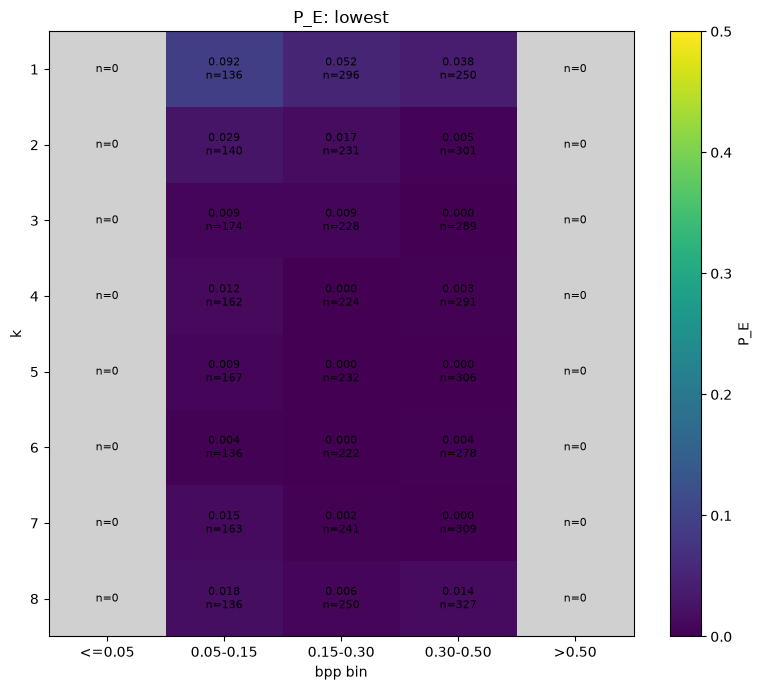

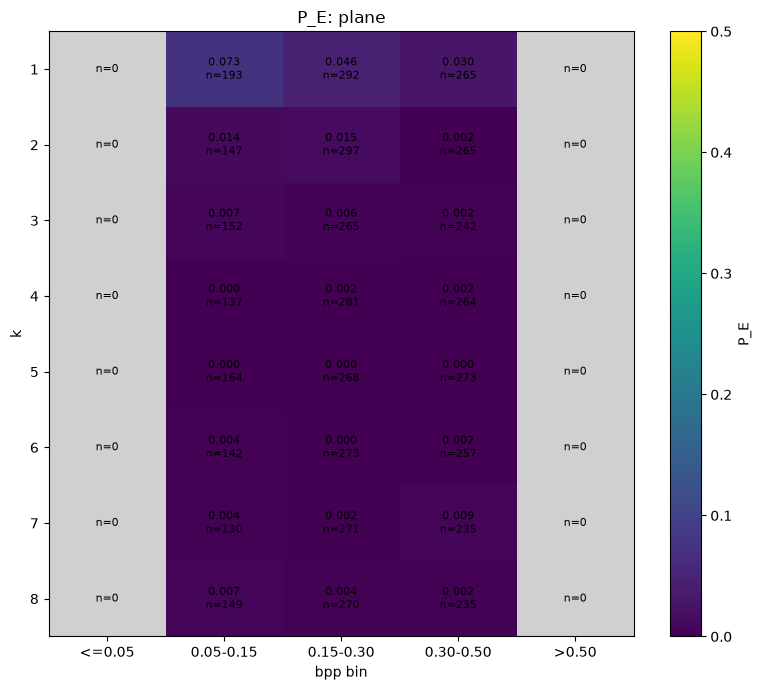

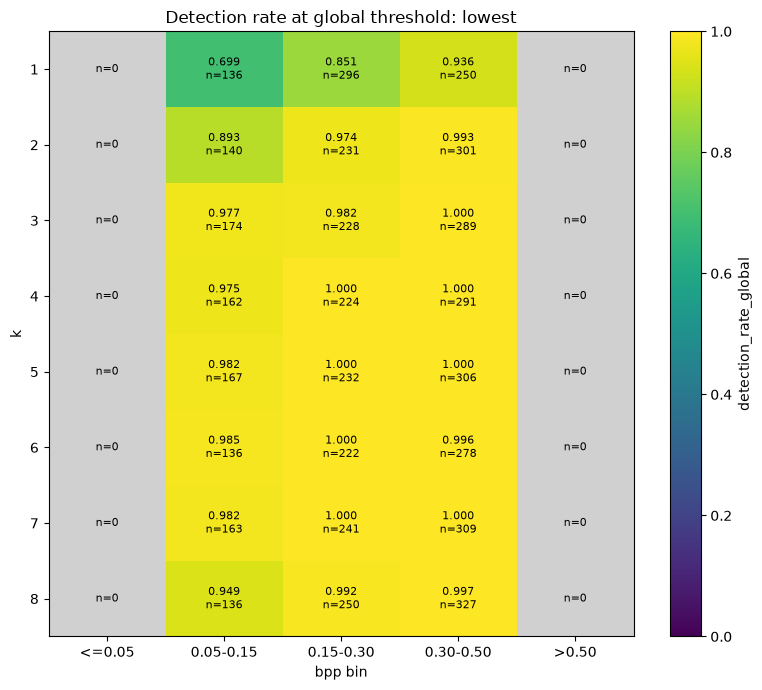

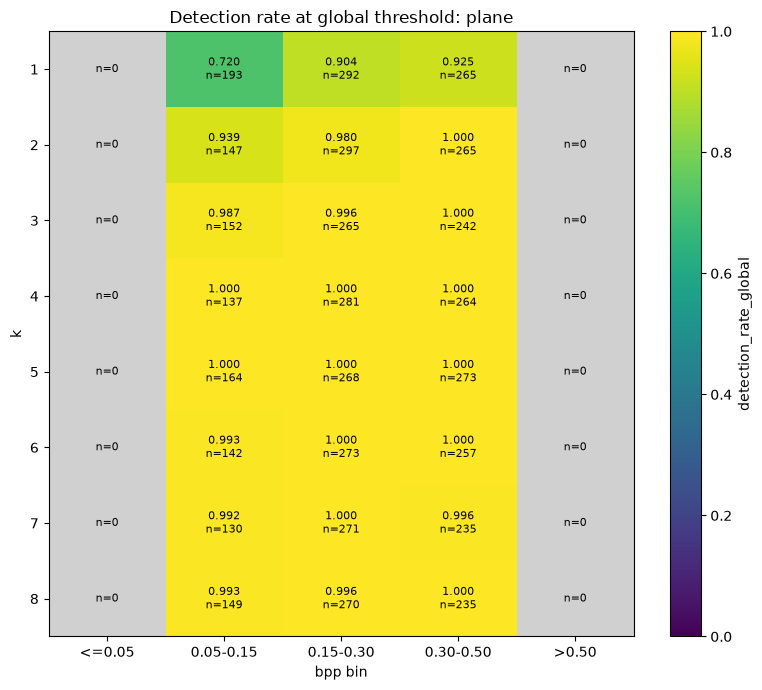

Saved heatmap: /srv/aai3001/AAI3001-CVDL/checkpoints/baseline_kv_xunet_v3_clip3_group_otf/test_predictions_heatmap_pe_lowest.png
Saved heatmap: /srv/aai3001/AAI3001-CVDL/checkpoints/baseline_kv_xunet_v3_clip3_group_otf/test_predictions_heatmap_pe_plane.png
Saved heatmap: /srv/aai3001/AAI3001-CVDL/checkpoints/baseline_kv_xunet_v3_clip3_group_otf/test_predictions_heatmap_detection_lowest.png
Saved heatmap: /srv/aai3001/AAI3001-CVDL/checkpoints/baseline_kv_xunet_v3_clip3_group_otf/test_predictions_heatmap_detection_plane.png
OUTPUT CHECK: predictions, per-setting CSV and four heatmaps written


In [16]:
# Run notebook 02 in its own namespace; do not change this training notebook's variables.
breakdown_notebook = json.loads((ROOT / "notebooks/02_eval_breakdown.ipynb").read_text())
breakdown_code = "\n\n".join("".join(cell["source"]) for cell in breakdown_notebook["cells"] if cell["cell_type"] == "code")
old_pred_path = os.environ.get("PRED_PATH")
os.environ["PRED_PATH"] = str(predictions_path)
try:
    exec(compile(breakdown_code, "02_eval_breakdown.ipynb", "exec"), {"__name__": "__main__"})
finally:
    if old_pred_path is None:
        os.environ.pop("PRED_PATH", None)
    else:
        os.environ["PRED_PATH"] = old_pred_path
assert predictions_path.with_name("test_predictions_per_setting.csv").exists()
assert len(list(checkpoint_dir.glob("test_predictions_heatmap_*.png"))) == 4
print("OUTPUT CHECK: predictions, per-setting CSV and four heatmaps written", flush=True)
